# Lab 4: Regression Analysis with Regularization Techniques

Student: Gyan Bahadur Tamang  
Course: MSCS 634 — Big Data and Data Mining  
Assignment: Lab 4  

This notebook compares simple linear, multiple linear, polynomial, Ridge, and Lasso regression using scikit-learn's Diabetes Dataset.

## Environment Setup

Run this cell first. Restart the kernel if packages are newly installed, then choose **Run All**.

In [12]:
%pip install -q pandas numpy matplotlib scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 1: Data Preparation

The Diabetes Dataset has 442 observations, ten numeric baseline measurements, and a continuous disease-progression target. Missing values and duplicates are checked before a reproducible 80/20 split.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures,StandardScaler

diabetes=load_diabetes(as_frame=True)
X=diabetes.data; y=diabetes.target
print('Shape:',X.shape)
print('Features:',X.columns.tolist())
print(X.describe())
print('Missing feature values:',int(X.isna().sum().sum()))
print('Missing target values:',int(y.isna().sum()))
print('Duplicate rows:',int(X.duplicated().sum()))
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)
print('Training:',X_train.shape,'Testing:',X_test.shape)

Shape: (442, 10)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  
mean   3.918434e-17 -5.777179e-18 -9.0425

## Shared Evaluation Function

Every model uses MAE, MSE, RMSE, and R² on the same test observations. Lower error values and higher R² indicate better predictive performance.

In [14]:
def evaluate_model(name,model,X_test_used):
    predictions=model.predict(X_test_used)
    mse=mean_squared_error(y_test,predictions)
    return {'Model':name,'MAE':mean_absolute_error(y_test,predictions),'MSE':mse,'RMSE':np.sqrt(mse),'R2':r2_score(y_test,predictions)},predictions

## Step 2: Linear Regression

BMI is selected as the single independent variable because it has a clear relationship with disease progression.

In [15]:
simple_model=LinearRegression().fit(X_train[['bmi']],y_train)
simple_metrics,simple_predictions=evaluate_model('Simple Linear (BMI)',simple_model,X_test[['bmi']])
pd.DataFrame([simple_metrics])

,Model,MAE,MSE,RMSE,R2
0,Simple Linear (BMI),52.259976,4061.825928,63.732456,0.23335


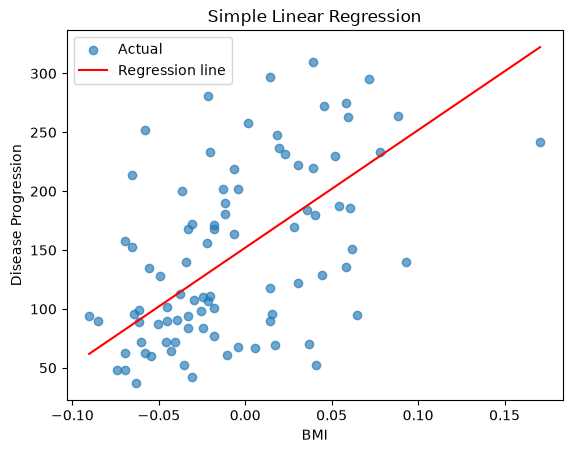

In [16]:
plt.scatter(X_test['bmi'],y_test,label='Actual',alpha=.65)
order=np.argsort(X_test['bmi'].to_numpy())
plt.plot(X_test['bmi'].to_numpy()[order],simple_predictions[order],color='red',label='Regression line')
plt.xlabel('BMI'); plt.ylabel('Disease Progression'); plt.title('Simple Linear Regression'); plt.legend(); plt.show()

## Step 3: Multiple Regression

All ten independent variables are used. Compared with BMI alone, the full model reduces RMSE and substantially increases test R².

In [17]:
multiple_model=LinearRegression().fit(X_train,y_train)
multiple_metrics,multiple_predictions=evaluate_model('Multiple Linear',multiple_model,X_test)
pd.DataFrame([multiple_metrics])

,Model,MAE,MSE,RMSE,R2
0,Multiple Linear,42.794095,2900.193628,53.853446,0.452603


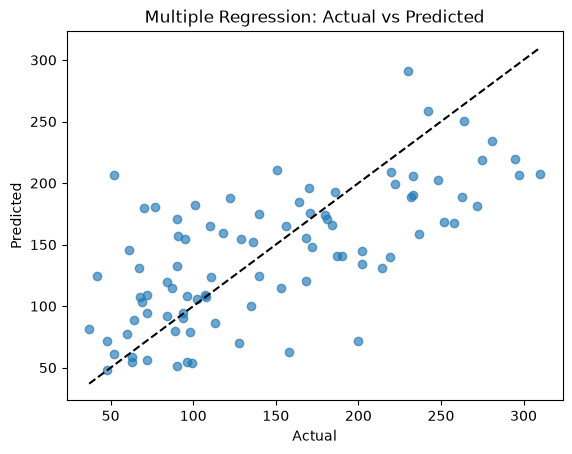

In [18]:
plt.scatter(y_test,multiple_predictions,alpha=.65)
lims=[min(y_test.min(),multiple_predictions.min()),max(y_test.max(),multiple_predictions.max())]
plt.plot(lims,lims,'k--'); plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Multiple Regression: Actual vs Predicted'); plt.show()

## Step 4: Polynomial Regression

Degrees 1–3 are applied to all ten predictors. Degree 1 is the multiple-linear baseline. Degree 2 modestly improves training fit but worsens test performance. Degree 3 sharply raises training R² while producing a negative test R², demonstrating severe overfitting.

In [19]:
polynomial_rows=[]
polynomial_models={}
for degree in [1,2,3]:
    model=make_pipeline(PolynomialFeatures(degree,include_bias=False),LinearRegression()).fit(X_train,y_train)
    row,pred=evaluate_model(f'Polynomial degree {degree}',model,X_test)
    row['Train R2']=r2_score(y_train,model.predict(X_train))
    polynomial_rows.append(row); polynomial_models[degree]=(model,pred)
polynomial_results=pd.DataFrame(polynomial_rows)
polynomial_results[['Model','Train R2','MAE','MSE','RMSE','R2']]

,Model,Train R2,MAE,MSE,RMSE,R2
0,Polynomial degree 1,0.527919,42.794095,2900.193628,53.853446,0.452603
1,Polynomial degree 2,0.606158,43.581693,3096.028307,55.641965,0.415640
2,Polynomial degree 3,0.856625,121.976702,32911.960666,181.416539,-5.211970


## Step 5: Regularization with Ridge and Lasso Regression

Both methods penalize coefficient magnitude. As alpha increases, Ridge shrinks all coefficients smoothly. Lasso can set coefficients exactly to zero, performing feature selection. Very large alpha causes underfitting; moderate values can improve generalization.

In [20]:
ridge_rows=[]; ridge_models={}
for alpha in [.01,.1,1,10,100]:
    model=make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(X_train,y_train)
    row,pred=evaluate_model(f'Ridge α={alpha:g}',model,X_test); row['Alpha']=alpha
    ridge_rows.append(row); ridge_models[alpha]=(model,pred)
lasso_rows=[]; lasso_models={}
for alpha in [.01,.1,1,10]:
    model=make_pipeline(StandardScaler(),Lasso(alpha=alpha,max_iter=20000)).fit(X_train,y_train)
    row,pred=evaluate_model(f'Lasso α={alpha:g}',model,X_test); row['Alpha']=alpha; row['Nonzero Coefficients']=np.count_nonzero(model[-1].coef_)
    lasso_rows.append(row); lasso_models[alpha]=(model,pred)
ridge_results=pd.DataFrame(ridge_rows); lasso_results=pd.DataFrame(lasso_rows)
display(ridge_results); display(lasso_results)

,Model,MAE,MSE,RMSE,R2,Alpha
0,Ridge α=0.01,42.794171,2900.075130,53.852346,0.452625,0.01
1,Ridge α=0.1,42.796235,2899.054556,53.842869,0.452818,0.10
2,Ridge α=1,42.811999,2892.014566,53.777454,0.454147,1.00
3,Ridge α=10,42.856825,2875.778718,53.626288,0.457211,10.00
4,Ridge α=100,43.250653,2858.224287,53.462363,0.460524,100.00


,Model,MAE,MSE,RMSE,R2,Alpha,Nonzero Coefficients
0,Lasso α=0.01,42.795018,2898.368019,53.836493,0.452947,0.01,10
1,Lasso α=0.1,42.805234,2884.624289,53.708698,0.455541,0.10,10
2,Lasso α=1,42.802984,2824.568094,53.146666,0.466877,1.00,9
3,Lasso α=10,44.764599,2933.834730,54.164885,0.446253,10.00,4


The lowest tested RMSE occurs at Ridge α=100 and Lasso α=1. Lasso α=10 retains only four nonzero coefficients and performs worse, illustrating excessive shrinkage and underfitting.

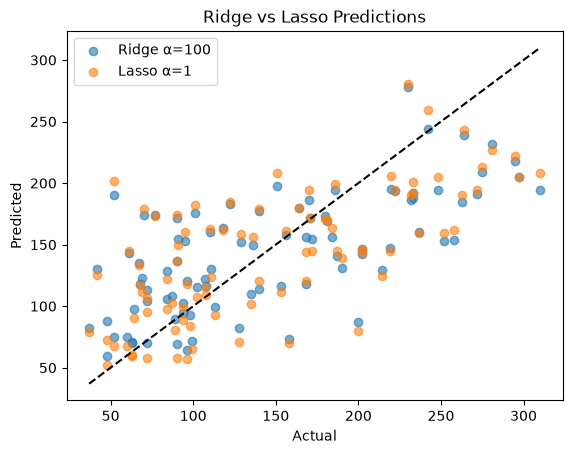

In [21]:
best_ridge_predictions=ridge_models[100][1]
best_lasso_predictions=lasso_models[1][1]
plt.scatter(y_test,best_ridge_predictions,alpha=.6,label='Ridge α=100')
plt.scatter(y_test,best_lasso_predictions,alpha=.6,label='Lasso α=1')
lims=[y_test.min(),y_test.max()]; plt.plot(lims,lims,'k--'); plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Ridge vs Lasso Predictions'); plt.legend(); plt.show()

## Step 6: Model Comparison and Analysis

In [22]:
comparison=pd.DataFrame([simple_metrics,multiple_metrics,polynomial_rows[1],dict(ridge_results.loc[ridge_results.RMSE.idxmin()].drop(labels='Alpha')),dict(lasso_results.loc[lasso_results.RMSE.idxmin()].drop(labels=['Alpha','Nonzero Coefficients']))])
comparison

,Model,MAE,MSE,RMSE,R2,Train R2
0,Simple Linear (BMI),52.259976,4061.825928,63.732456,0.233350,NaN
1,Multiple Linear,42.794095,2900.193628,53.853446,0.452603,NaN
2,Polynomial degree 2,43.581693,3096.028307,55.641965,0.415640,0.606158
3,Ridge α=100,43.250653,2858.224287,53.462363,0.460524,NaN
4,Lasso α=1,42.802984,2824.568094,53.146666,0.466877,NaN


### Key Observations

- The BMI-only model explains limited target variation (R² 0.233). Using all features improves R² to 0.453.
- Polynomial degree 2 does not outperform multiple linear regression, and degree 3 severely overfits: training R² rises to 0.857, but test R² falls to -5.212.
- Ridge reduces coefficient variance and slightly improves performance as alpha increases across the tested range.
- Lasso α=1 produces the best tested result (R² 0.467, RMSE 53.15) while setting one coefficient to zero.
- Diabetes progression is only partly predictable from these ten baseline variables; regularization improves stability, but substantial unexplained variation remains.

### Conclusion

Among the tested configurations, Lasso α=1 performs best. The experiment demonstrates the bias–variance tradeoff: excessive polynomial flexibility overfits, whereas moderate regularization slightly improves generalization.